# Sentinel-1/2: PDF (histograms), LSB steganography and compressive sensing

Contents:
1. Getting Sentinel-2 and Sentinel-1 data from the Copernicus Data Space Ecosystem
2. **Task 1** – histograms (PDF) of S2 and S1 bands for a natural and an urban area
3. **Task 2** – steganography: random 2 LSBs, quality assessment, histograms, detection
4. **Task 3 (optional)** – compressive sensing and its use in EO

In [1]:
!pip install -q sentinelhub rasterio scikit-image scipy matplotlib numpy pandas

In [2]:
import getpass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
np.random.seed(42)   # reproducible results

## 1. Data acquisition (Copernicus Data Space Ecosystem)

Two small areas (about 4 × 4 km) are used, so that the data are light and come from a single scene:

| Area | Description | Bounding box (lon_min, lat_min, lon_max, lat_max) |
|---|---|---|
| **urban** | Kraków city centre | 19.91, 50.04, 19.97, 50.08 |
| **natural** | Niepołomice Forest | 20.33, 50.08, 20.39, 50.12 |


**Preferred method – Sentinel Hub Process API on CDSE** (no large downloads, the service returns only the cropped area):

1. Log in at <https://shapps.dataspace.copernicus.eu/dashboard/>
2. *User settings → OAuth clients → Create new* – copy the **client ID** and **client secret** (the secret is shown only once).
3. Run the cells below and paste both values when asked (they are not stored in the notebook).

A fallback that works with files downloaded by hand is described right after.

In [14]:
from sentinelhub import (SHConfig, SentinelHubRequest, DataCollection, BBox, CRS,
                         MimeType, bbox_to_dimensions)

config = SHConfig()
config.sh_client_id = getpass.getpass("CDSE OAuth client ID:")
config.sh_client_secret = getpass.getpass("CDSE OAuth client secret: = ")
config.sh_base_url = "https://sh.dataspace.copernicus.eu"
config.sh_token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"

S2_COL = DataCollection.SENTINEL2_L2A.define_from("s2l2a_cdse", service_url=config.sh_base_url)
S1_COL = DataCollection.SENTINEL1_IW.define_from("s1iw_cdse", service_url=config.sh_base_url)

CDSE OAuth client ID:··········
CDSE OAuth client secret: = ··········


In [15]:
AREAS = {
    "urban":   (19.91, 50.04, 19.97, 50.08),
    "natural": (20.33, 50.08, 20.39, 50.12),
}
TIME_INTERVAL = ("2025-06-01", "2025-08-31")     # summer: few clouds, full vegetation
RES = 10                                          # metres per pixel

S2_BANDS = ["B02", "B03", "B04", "B08", "B11"]
EVAL_S2 = '''
//VERSION=3
function setup() {
  return {input: [{bands: ["B02","B03","B04","B08","B11"], units: "REFLECTANCE"}],
          output: {bands: 5, sampleType: "FLOAT32"}};
}
function evaluatePixel(s) { return [s.B02, s.B03, s.B04, s.B08, s.B11]; }
'''
EVAL_S1 = '''
//VERSION=3
function setup() {
  return {input: [{bands: ["VV","VH"]}],
          output: {bands: 2, sampleType: "FLOAT32"}};
}
function evaluatePixel(s) { return [s.VV, s.VH]; }      // linear sigma0
'''

def load_s2(bbox):
    """Returns {band: 2D reflectance array (0-1)} - least cloudy S2 L2A mosaic in TIME_INTERVAL."""
    bb = BBox(bbox, crs=CRS.WGS84)
    req = SentinelHubRequest(
        evalscript=EVAL_S2,
        input_data=[SentinelHubRequest.input_data(
            S2_COL, time_interval=TIME_INTERVAL, mosaicking_order="leastCC", maxcc=0.1)],
        responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
        bbox=bb, size=bbox_to_dimensions(bb, resolution=RES), config=config)
    arr = req.get_data()[0]                                  # (H, W, 5)
    return {b: np.clip(arr[..., i], 0, 1) for i, b in enumerate(S2_BANDS)}

def load_s1(bbox):
    """Returns {pol: 2D array in dB} - orthorectified S1 IW GRD (sigma0 ellipsoid), dual-pol VV+VH."""
    bb = BBox(bbox, crs=CRS.WGS84)
    req = SentinelHubRequest(
        evalscript=EVAL_S1,
        input_data=[SentinelHubRequest.input_data(
            S1_COL, time_interval=TIME_INTERVAL,
            other_args={"dataFilter": {"acquisitionMode": "IW", "polarization": "DV"},
                        "processing": {"backCoeff": "SIGMA0_ELLIPSOID", "orthorectify": True,
                                       "demInstance": "COPERNICUS_30"}})],
        responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
        bbox=bb, size=bbox_to_dimensions(bb, resolution=RES), config=config)
    arr = req.get_data()[0]                                  # (H, W, 2) linear
    out = {}
    for i, p in enumerate(["vv", "vh"]):
        lin = np.where(arr[..., i] > 0, arr[..., i], np.nan)
        out[p] = 10 * np.log10(lin)                          # dB
    return out

s2 = {name: load_s2(bb) for name, bb in AREAS.items()}
s1 = {name: load_s1(bb) for name, bb in AREAS.items()}
print({a: s2[a]["B04"].shape for a in s2})

{'urban': (439, 436), 'natural': (441, 433)}


## 2. Task 1 – PDF (histograms) of Sentinel data

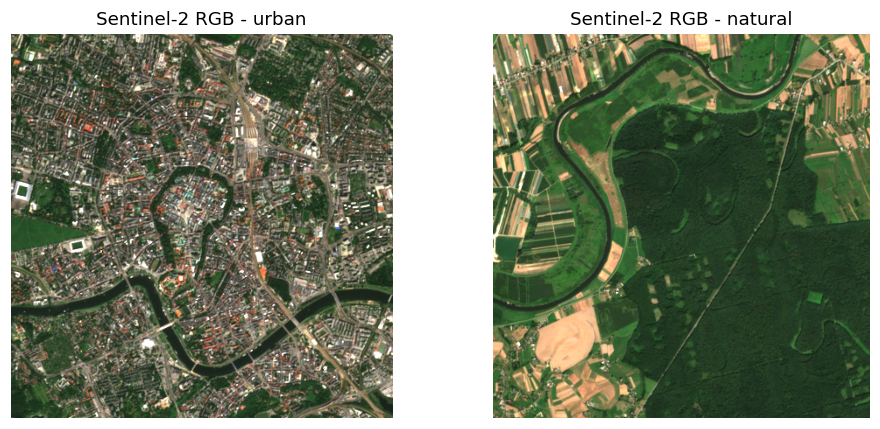

In [16]:
def show_rgb(d, title):
    rgb = np.dstack([d["B04"], d["B03"], d["B02"]])
    rgb = np.clip(rgb / np.nanpercentile(rgb, 99), 0, 1)
    plt.imshow(rgb); plt.title(title); plt.axis("off")

plt.figure(figsize=(9, 4))
for i, name in enumerate(AREAS, 1):
    plt.subplot(1, 2, i); show_rgb(s2[name], f"Sentinel-2 RGB - {name}")
plt.tight_layout(); plt.show()

### 2a. Sentinel-2 – band histograms

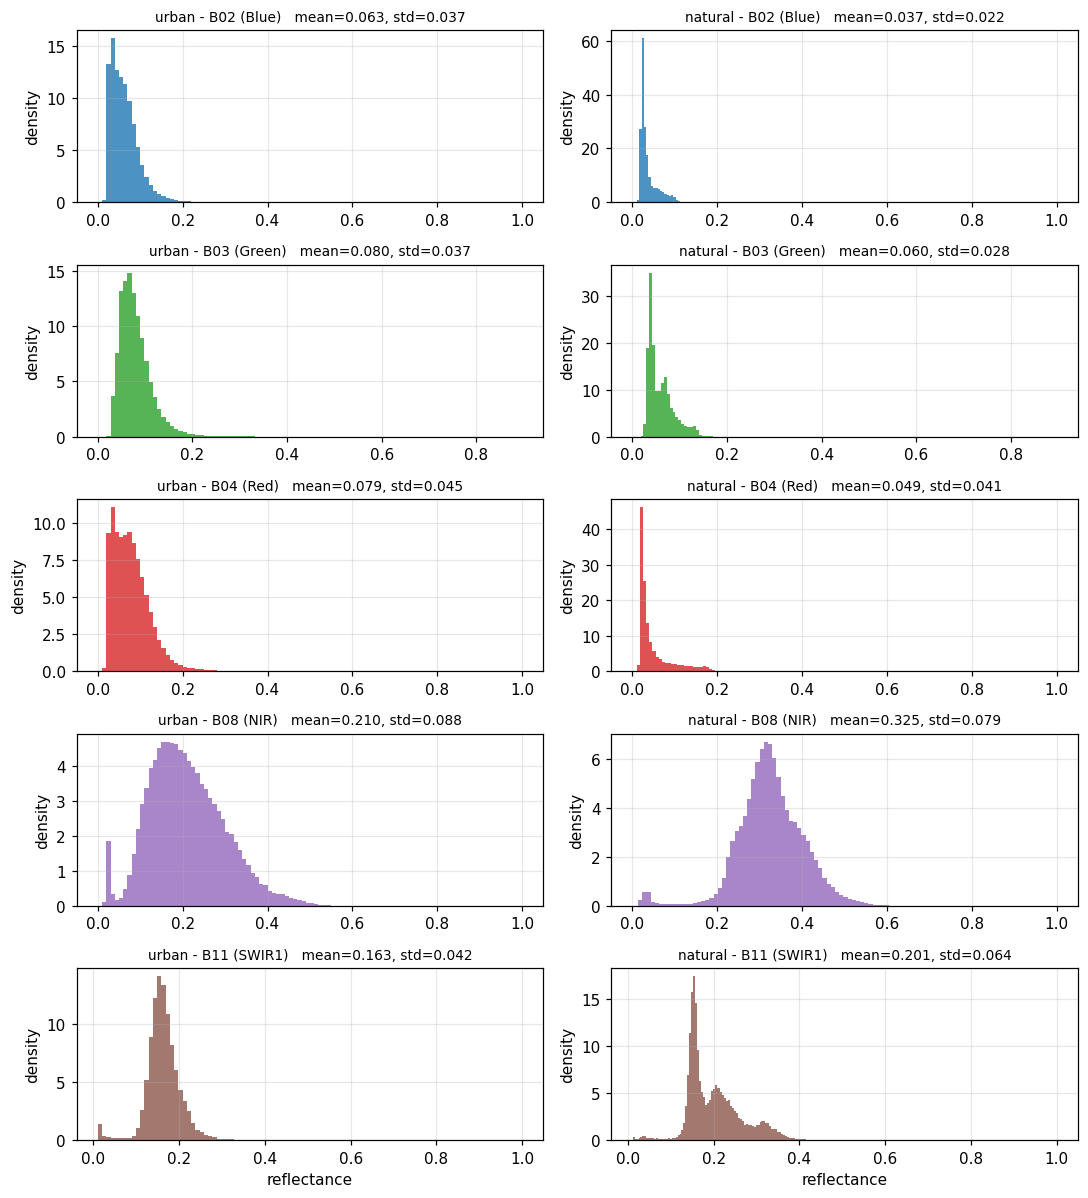

In [18]:
BANDS = {"B02": ("Blue", "tab:blue"), "B03": ("Green", "tab:green"),
         "B04": ("Red", "tab:red"), "B08": ("NIR", "tab:purple"), "B11": ("SWIR1", "tab:brown")}

def plot_hist_s2(areas=("urban", "natural"), bins=100):
    fig, axes = plt.subplots(len(BANDS), len(areas), figsize=(10, 2.2 * len(BANDS)), sharex="row")
    for r, (b, (lab, col)) in enumerate(BANDS.items()):
        for c, a in enumerate(areas):
            x = s2[a][b].ravel()
            ax = axes[r, c]
            ax.hist(x, bins=bins, density=True, color=col, alpha=.8)
            ax.set_title(f"{a} - {b} ({lab})   mean={x.mean():.3f}, std={x.std():.3f}", fontsize=9)
            ax.set_ylabel("density")
    for c in range(len(areas)): axes[-1, c].set_xlabel("reflectance")
    plt.tight_layout(); plt.show()

plot_hist_s2()

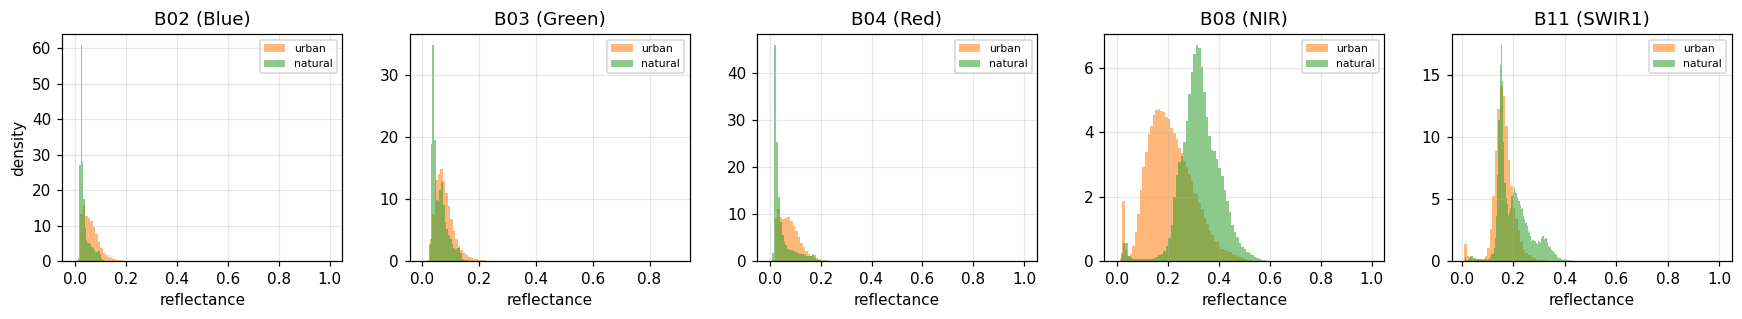

,area,band,mean,std,skew,kurtosis
0,urban,B02,0.063,0.037,2.762,20.945
1,urban,B03,0.080,0.037,2.579,15.928
2,urban,B04,0.079,0.045,1.863,9.892
3,urban,B08,0.210,0.088,0.506,0.381
4,urban,B11,0.163,0.042,0.421,11.480
5,natural,B02,0.037,0.022,2.530,16.354
6,natural,B03,0.060,0.028,1.612,6.848
7,natural,B04,0.049,0.041,1.972,4.234
8,natural,B08,0.325,0.079,-0.498,2.338
9,natural,B11,0.201,0.064,0.732,0.566


In [19]:
# Both areas on one plot (differences are easier to see)
fig, axes = plt.subplots(1, len(BANDS), figsize=(16, 3))
for ax, (b, (lab, _)) in zip(axes, BANDS.items()):
    for a, col in zip(AREAS, ["tab:orange", "tab:green"]):
        ax.hist(s2[a][b].ravel(), bins=100, density=True, alpha=.55, label=a, color=col)
    ax.set_title(f"{b} ({lab})"); ax.legend(fontsize=7)
    ax.set_xlabel("reflectance")
axes[0].set_ylabel("density")
plt.tight_layout(); plt.show()

# Summary statistics: skewness and kurtosis
rows = []
for a in AREAS:
    for b in BANDS:
        x = s2[a][b].ravel()
        rows.append(dict(area=a, band=b, mean=x.mean(), std=x.std(),
                         skew=stats.skew(x), kurtosis=stats.kurtosis(x)))
pd.DataFrame(rows).round(3)

### Observations – Sentinel-2

**Shape of the histograms.** The visible bands (B02, B03, B04) are unimodal in both areas: one sharp peak at low reflectance (about 0.02–0.1) followed by a long tail to the right. The peak comes from dark surfaces (water, dense forest, shadows). The tail comes from brighter objects (roofs, roads, bare soil, harvested fields). NIR (B08) and SWIR (B11) show clearer mixtures of land-cover classes:
- *Urban B08* has a broad main mode at about 0.17–0.2 and a small separate spike near 0.02. The spike is water (the Vistula), which absorbs almost all NIR.
- *Natural B08* has a main mode at about 0.33 (forest and fields) and a small low-reflectance bump at about 0.03 (river and oxbow lakes).
- *Natural B11* is multimodal: a main peak at about 0.15 (dense forest), a shoulder at about 0.2–0.25 and a second bump at about 0.3 (bare soil and dry or harvested fields).
- *Urban B11* has a narrow main peak at about 0.16 and a tiny bump near 0.01 (water).

So the multimodality is a direct consequence of the mixture of surface types in the scene. The histogram can be seen as a weighted sum of the PDFs of individual classes.

**Visible bands vs. NIR.** Forest is dark in blue and red (mean 0.037 and 0.049) because chlorophyll absorbs strongly in these wavelengths. It is much brighter in NIR (mean 0.325), because the internal leaf structure scatters NIR strongly (the "red edge" jump around 700–750 nm). The small bump in green (B03 mean 0.060 > B04 mean 0.049) is the "green peak" of vegetation. The ratio of the means gives a rough NDVI of ≈ 0.74 for the natural area, versus ≈ 0.45 for the urban area, which mixes vegetation with impervious surfaces. In the urban area the visible bands are higher and the NIR is lower, because asphalt, concrete and roofs reflect similarly in all bands and there is less vegetation. Water behaves in the opposite way to vegetation: it is dark everywhere and nearly black in NIR and SWIR.

**Urban vs. natural area (spread).** In absolute terms the urban area has the wider distribution in B02, B03, B04 and B08 (std 0.037/0.037/0.045/0.088 vs. 0.022/0.028/0.041/0.079). The city is a mosaic of very different materials: parks, water, red roofs, concrete, shadows between buildings. The exception is B11, where the natural area is wider (0.064 vs. 0.042), because dark moist forest and dry bare fields differ strongly in SWIR (SWIR is sensitive to moisture). In the natural area the visible bands are dominated by one class (forest), so their absolute std is small. Relative to the mean, however, the spread of red is large there (std/mean ≈ 0.84 vs. 0.57 in the city), because of the contrast between dark forest and bright bare fields.

**Skewness and kurtosis.** The visible bands are strongly right-skewed (skewness 1.6–2.8) with heavy tails. The excess kurtosis (scipy uses Fisher's definition, so a normal distribution gives 0) is very high for urban B02 (20.9) and B03 (15.9). This is expected for reflectance, which is bounded below by 0 and has a tail of a few bright objects, so the distribution looks more log-normal than Gaussian. B08 is nearly symmetric (urban skew 0.51; natural skew −0.50, with a slight left tail caused by water). Urban B11 has a modest skewness (0.42) but a high kurtosis (11.5), because of its narrow main peak with water outliers at very low values.

**Closeness to a normal distribution.** The closest to normal is **B08 (NIR)**: urban B08 has skewness 0.51 and excess kurtosis 0.38, and natural B08 has −0.50 and 2.34. Its main mode is bell-shaped, although a water bump or tail is visible in both areas. Natural B11 (skewness 0.73, kurtosis 0.57) is also numerically close, but its histogram has shoulders and a second bump, so it is not really Gaussian. The visible bands are far from normal in both areas. Overall, none of the bands is exactly Gaussian: real scenes are mixtures of classes, so the PDF of a whole image is generally not a single standard distribution.

### 2b. Sentinel-1 – histograms (VV, VH, in dB)

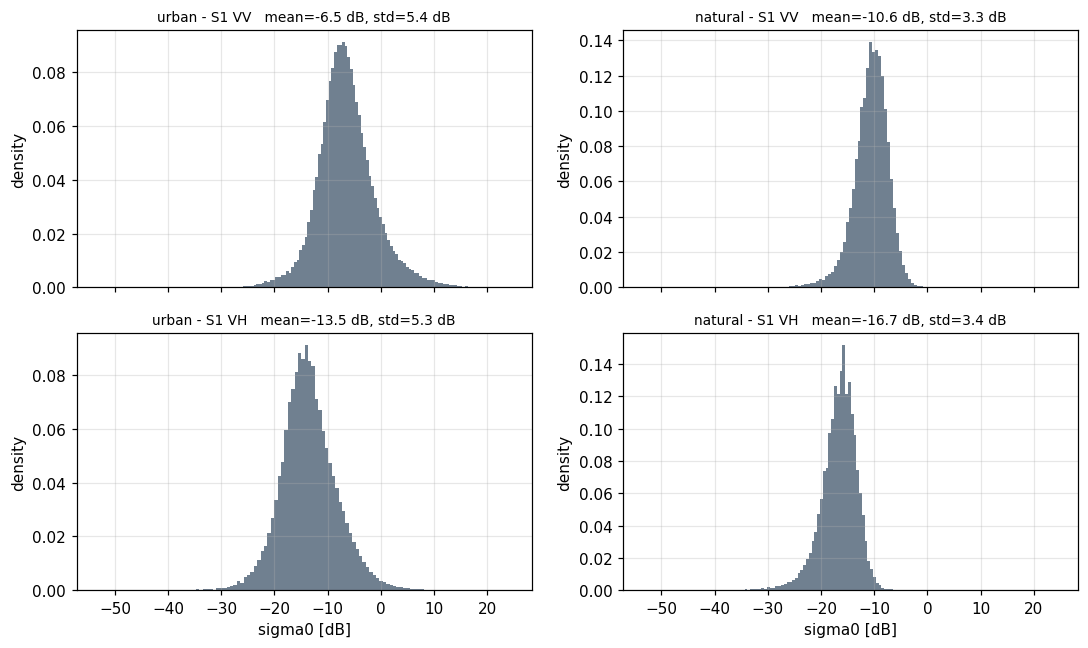

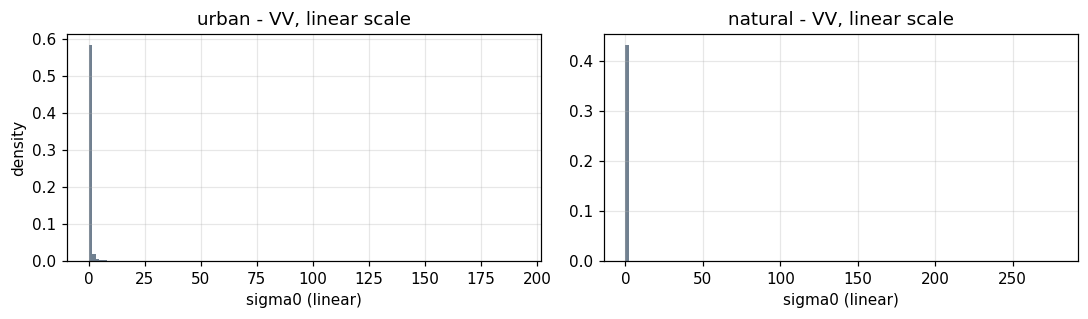

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for c, a in enumerate(AREAS):
    for r, p in enumerate(["vv", "vh"]):
        x = s1[a][p].ravel(); x = x[np.isfinite(x)]
        axes[r, c].hist(x, bins=120, density=True, color="slategray")
        axes[r, c].set_title(f"{a} - S1 {p.upper()}   mean={x.mean():.1f} dB, std={x.std():.1f} dB", fontsize=9)
        axes[r, c].set_ylabel("density")
axes[1, 0].set_xlabel("sigma0 [dB]"); axes[1, 1].set_xlabel("sigma0 [dB]")
plt.tight_layout(); plt.show()

# For comparison: linear scale (shows the skewness caused by speckle)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, a in zip(axes, AREAS):
    lin = 10 ** (s1[a]["vv"][np.isfinite(s1[a]["vv"])] / 10)
    ax.hist(lin, bins=120, density=True, color="slategray"); ax.set_title(f"{a} - VV, linear scale")
    ax.set_xlabel("sigma0 (linear)")
axes[0].set_ylabel("density")
plt.tight_layout(); plt.show()

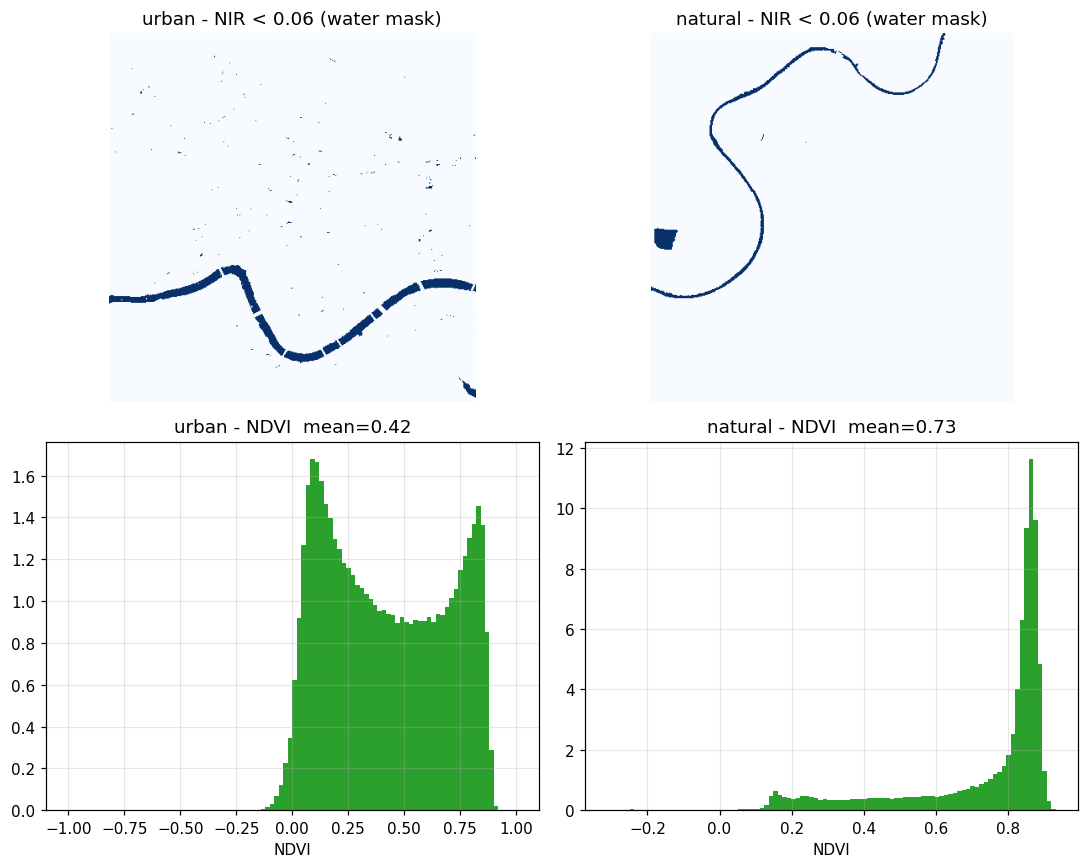

In [26]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
for c, a in enumerate(AREAS):
    nir, red = s2[a]["B08"], s2[a]["B04"]
    ndvi = (nir - red) / (nir + red + 1e-9)
    ax[0, c].imshow(nir < 0.06, cmap="Blues"); ax[0, c].set_title(f"{a} - NIR < 0.06 (water mask)"); ax[0, c].axis("off")
    ax[1, c].hist(ndvi.ravel(), bins=100, density=True, color="tab:green")
    ax[1, c].set_title(f"{a} - NDVI  mean={ndvi.mean():.2f}"); ax[1, c].set_xlabel("NDVI")
plt.tight_layout(); plt.show()

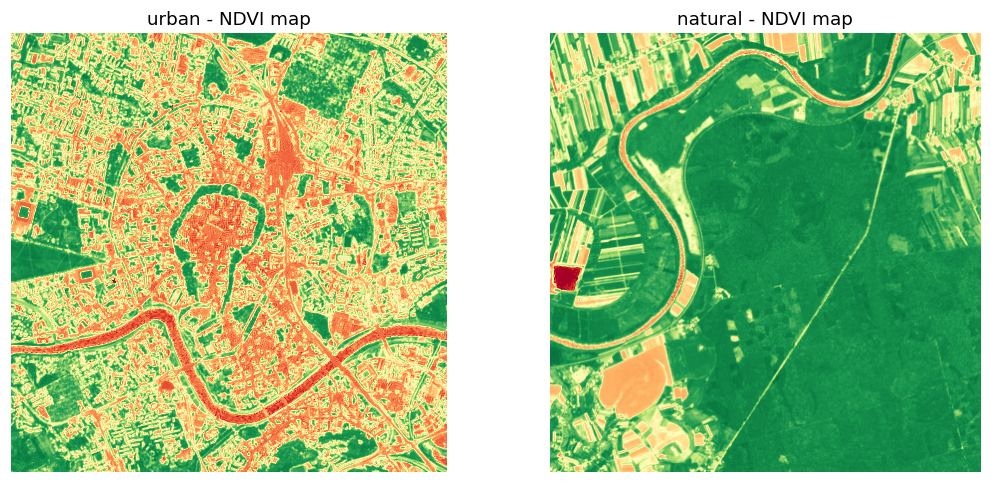

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
for a_, name in zip(ax, AREAS):
    ndvi = (s2[name]["B08"] - s2[name]["B04"]) / (s2[name]["B08"] + s2[name]["B04"] + 1e-9)
    a_.imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.95)
    a_.set_title(f"{name} - NDVI map"); a_.axis("off")
plt.tight_layout(); plt.show()

### Observations – Sentinel-1

**Shape of the histograms (dB vs. linear, speckle).** In dB scale all four S1 histograms (VV and VH, urban and natural) are unimodal and bell-shaped, close to symmetric, which is very different from the S2 histograms. The S2 histograms are right-skewed or multimodal because they reflect a mixture of land-cover classes. In S1 the spread is dominated by speckle, a multiplicative noise that comes from the coherent summation of many scatterers inside a resolution cell. Taking the logarithm turns multiplicative noise into additive noise, which is why the dB histograms are much more regular. In linear scale the same data are extremely skewed: almost all pixels fall into the first bin (σ⁰ ≈ 0–1), while a very long tail reaches σ⁰ ≈ 190 in the urban area and ≈ 280 in the natural area (≈ 23–24 dB). These extreme values come from a few very strong scatterers (corner reflectors, metal structures), so the linear histogram is practically unreadable and the dB scale is the standard way of displaying and analysing SAR data. Part of the width of each histogram is pure speckle, not real variation of the terrain. For multilooked IW GRD data it is roughly 2 dB, so the true class contrast is smaller than the std suggests.

**VV vs. VH.** VH is lower than VV in both areas, by about 7 dB in the urban area (−6.5 vs. −13.5 dB) and about 6 dB in the natural area (−10.6 vs. −16.7 dB). The reason is that VV is a co-polarised channel, dominated by direct (surface or double-bounce) scattering, while VH (cross-polarised) is produced only when the scatterer changes the polarisation of the wave, which happens mostly through multiple scattering and depolarisation. The VV–VH difference is slightly smaller over the forest, since the canopy (volume scattering) depolarises the signal and raises VH relative to VV. Over smooth surfaces and regular buildings the response is mainly co-polarised, so the difference is larger. Both channels have similar shapes and spreads (urban std ≈ 5.3–5.4 dB, natural ≈ 3.3–3.4 dB), shifted by a roughly constant offset.

**City vs. forest.** The urban histograms are wider (std 5.4 dB vs. 3.3 dB in VV) and shifted to higher values (mean −6.5 dB vs. −10.6 dB in VV). The urban VV histogram has a long tail towards high values, up to about +15–20 dB, which is caused by the double-bounce between walls and the ground and by strong scatterers (roofs, metal structures, railway infrastructure). The tail on the low side (down to −30 dB and below) comes from radar shadows behind buildings, smooth asphalt and the Vistula, where the specular reflection sends the signal away from the sensor. The forest is a more homogeneous target: the histogram is narrow, centred at about −10.6 dB (VV) and −16.7 dB (VH), with a small left tail from the river, oxbow lakes and smooth, bare fields. The mean of the forest is not extremely high because the Sentinel-1 C-band signal (5.4 GHz, wavelength ≈ 5.5 cm) interacts mainly with the upper canopy and does not penetrate deep.

**Comparison with Sentinel-2.** S1 carries different information about the same terrain. S2 measures reflected sunlight, so it is sensitive to pigments, leaf water content and material colour. This is why the S2 histograms (and the NDVI histograms: bimodal in the city with peaks near 0.1 and 0.8, and one strong peak at ≈ 0.85 in the forest) separate vegetation from impervious surfaces so clearly. S1 is an active microwave measurement. It is sensitive to surface roughness, geometry (double-bounce, shadow), structure of the vegetation and dielectric properties (moisture), and it does not depend on sunlight or clouds. Because of this, classes that are easy to separate in S2 can overlap in S1. For example, water is clearly visible as a separate bump in the NIR histograms and in the water mask (NIR < 0.06). In the S1 histograms it does not form a separate mode but only a weak left tail, because the river covers a small fraction of the image and speckle blurs the contrast. On the other hand, S1 separates things S2 cannot, such as built-up structures with strong double-bounce or surface roughness differences that are invisible in optical bands. The two sensors are therefore complementary, and in practice they are often used together for land-cover classification and for monitoring in cloudy conditions.

## 3. Task 2 – Steganography (replacing the 2 least significant bits with random values)

We take the red band (B04) of the urban area, scale it to 8 bits, and **in every pixel** replace the two least significant bits
with a random number from 0-3 (drawn independently for each pixel).

In [21]:
def to_uint8(x, lo=2, hi=98):
    a, b = np.nanpercentile(x, [lo, hi])
    return (np.clip((x - a) / (b - a), 0, 1) * 255).astype(np.uint8)

orig = to_uint8(s2["urban"]["B04"])

def embed_random_lsb(img, nbits=2, rng=np.random.default_rng(0)):
    mask = 0xFF ^ ((1 << nbits) - 1)                                # 0b11111100 for nbits=2
    rnd = rng.integers(0, 2 ** nbits, img.shape, dtype=np.uint8)    # random 0..3, different for every pixel
    return (img & mask) | rnd

stego = embed_random_lsb(orig, nbits=2)

print("max |difference| =", np.abs(orig.astype(int) - stego.astype(int)).max(), "grey levels")

max |difference| = 3 grey levels


### 3a. Visual quality

PSNR = 44.09 dB
SSIM = 0.9973


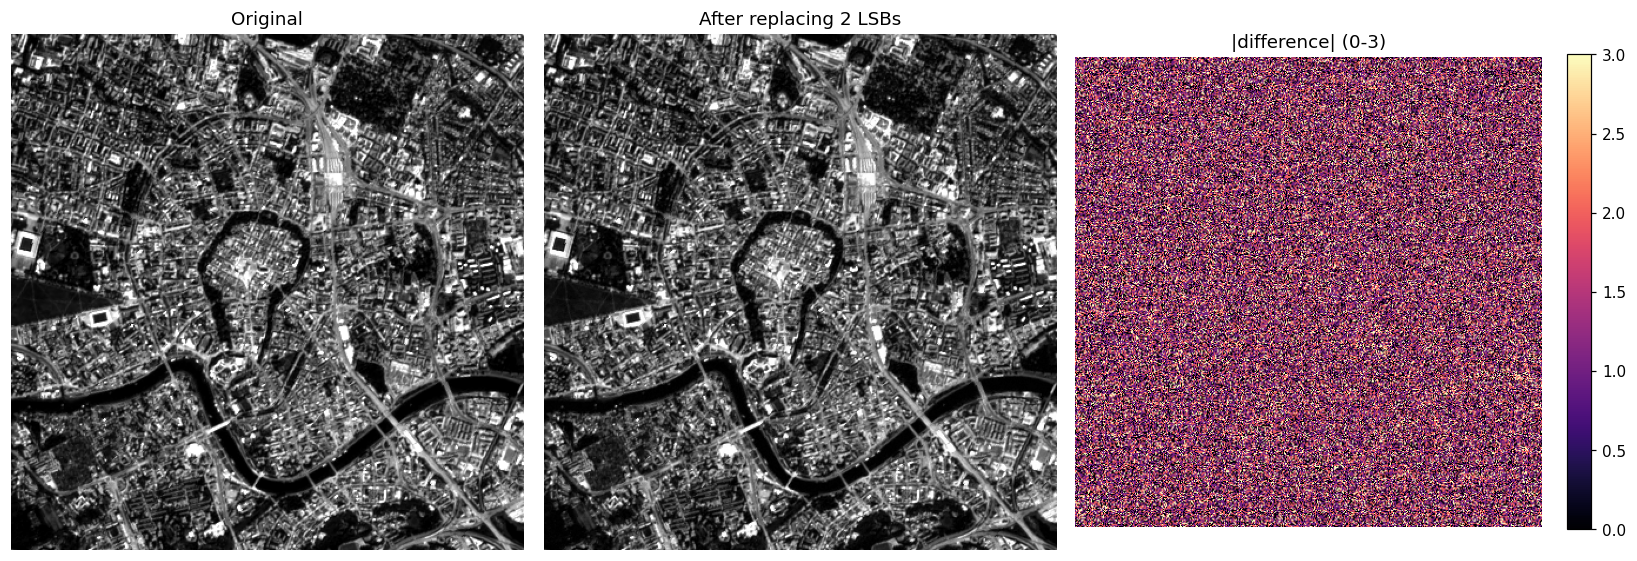

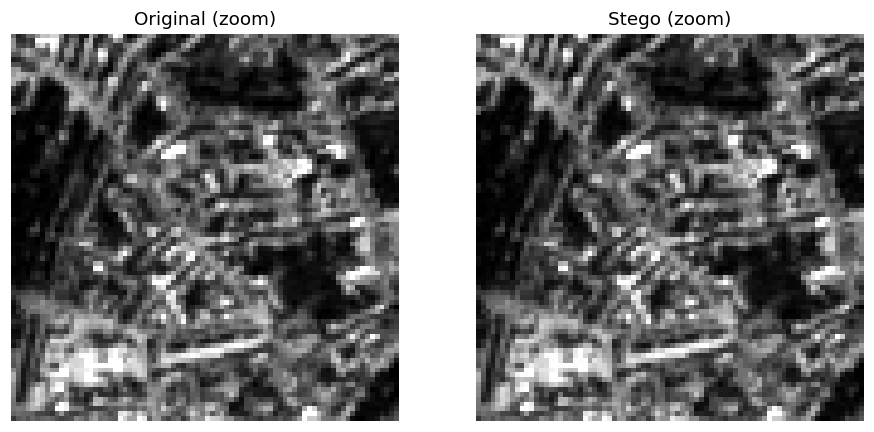

In [22]:
from skimage.metrics import structural_similarity as ssim

def psnr(a, b):
    mse = np.mean((a.astype(float) - b.astype(float)) ** 2)
    return 10 * np.log10(255 ** 2 / mse)

print(f"PSNR = {psnr(orig, stego):.2f} dB")
print(f"SSIM = {ssim(orig, stego, data_range=255):.4f}")

diff = np.abs(orig.astype(int) - stego.astype(int))
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(orig, cmap="gray"); ax[0].set_title("Original")
ax[1].imshow(stego, cmap="gray"); ax[1].set_title("After replacing 2 LSBs")
im = ax[2].imshow(diff, cmap="magma"); ax[2].set_title("|difference| (0-3)")
plt.colorbar(im, ax=ax[2], fraction=.046)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# 80x80 px zoom - differences are easiest to see here
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(orig[100:180, 100:180], cmap="gray", vmin=0, vmax=255); ax[0].set_title("Original (zoom)")
ax[1].imshow(stego[100:180, 100:180], cmap="gray", vmin=0, vmax=255); ax[1].set_title("Stego (zoom)")
for a in ax: a.axis("off")
plt.show()

### 3b. PDF (histogram) of the original and the manipulated image

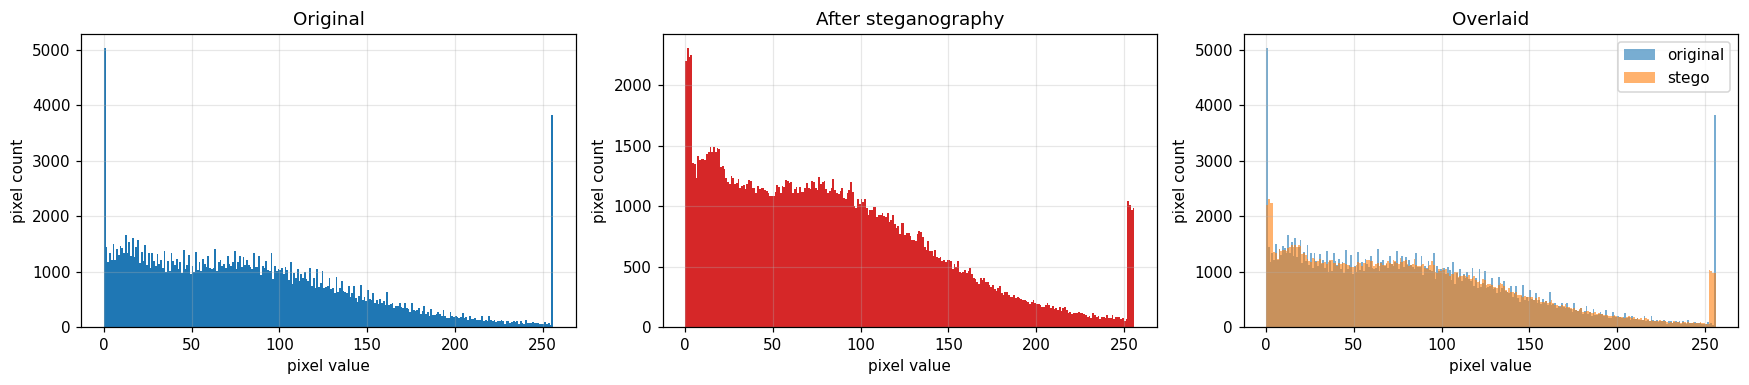

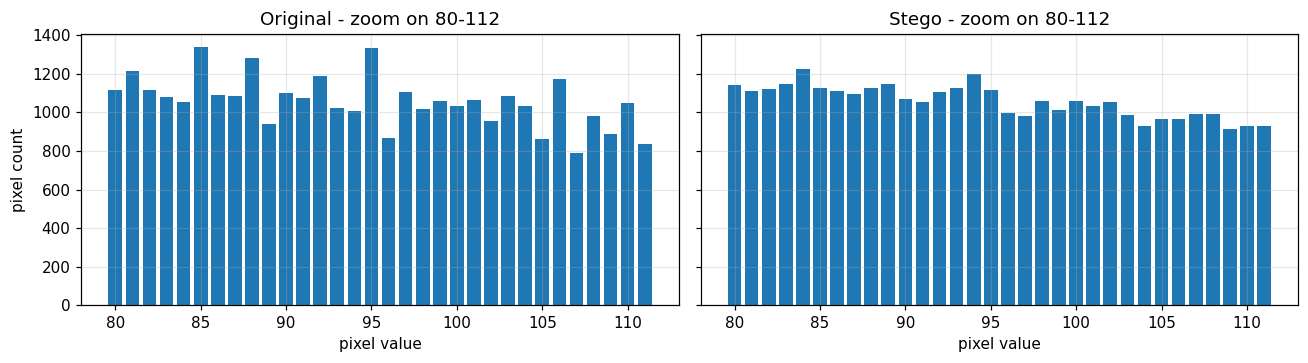

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].hist(orig.ravel(), bins=256, range=(0, 256), color="tab:blue");  ax[0].set_title("Original")
ax[1].hist(stego.ravel(), bins=256, range=(0, 256), color="tab:red");  ax[1].set_title("After steganography")
ax[2].hist(orig.ravel(), bins=256, range=(0, 256), alpha=.6, label="original")
ax[2].hist(stego.ravel(), bins=256, range=(0, 256), alpha=.6, label="stego"); ax[2].legend()
ax[2].set_title("Overlaid")
for a in ax: a.set_xlabel("pixel value"); a.set_ylabel("pixel count")
plt.tight_layout(); plt.show()

# Zoom on a narrow range - the "staircase" pattern is visible here
lo, hi = 80, 112
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for a, im_, t in zip(ax, [orig, stego], ["Original", "Stego"]):
    h = np.bincount(im_.ravel(), minlength=256)
    a.bar(range(lo, hi), h[lo:hi]); a.set_title(f"{t} - zoom on {lo}-{hi}")
    a.set_xlabel("pixel value")
ax[0].set_ylabel("pixel count")
plt.tight_layout(); plt.show()

### 3c. Can the manipulation be detected? – chi-square test and a 'staircase' measure

In [24]:
def chi_square_lsb(img, nbits=2):
    """Chi-square test for equalisation of the histogram inside groups of 2^nbits neighbouring values.
    Random LSBs -> counts inside a group (4k..4k+3) become almost equal -> small chi2 statistic.
    Returns (chi2, p_embedded); p close to 1 means the histogram is suspiciously 'flattened'."""
    g = 2 ** nbits
    h = np.bincount(img.ravel(), minlength=256).astype(float).reshape(-1, g)
    expected = h.mean(axis=1, keepdims=True) * np.ones_like(h)
    ok = expected > 5                                            # standard validity condition of the chi2 test
    chi = (((h - expected) ** 2)[ok] / expected[ok]).sum()
    dof = ok.sum() - ok.any(axis=1).sum()
    return chi, 1 - stats.chi2.cdf(chi, dof)

def staircase(img, nbits=2):
    """Mean relative spread of counts inside each group - small value = flattened histogram."""
    g = 2 ** nbits
    h = np.bincount(img.ravel(), minlength=256).astype(float).reshape(-1, g)
    return np.mean(h.std(axis=1) / (h.mean(axis=1) + 1e-9))

for name, im_ in [("original", orig), ("stego", stego)]:
    chi, p = chi_square_lsb(im_)
    print(f"{name:9s}  chi2={chi:10.1f}   p(embedded)={p:.4f}   staircase={staircase(im_):.4f}")

original   chi2=   17665.8   p(embedded)=0.0000   staircase=0.1605
stego      chi2=     192.9   p(embedded)=0.4683   staircase=0.0402


In [28]:
def chi_square_inner(img, nbits=2):
    """Same chi2 test, but ignoring the clipped end groups (0-3 and 252-255)."""
    g = 2 ** nbits
    h = np.bincount(img.ravel(), minlength=256).astype(float)[g:256 - g].reshape(-1, g)
    expected = h.mean(axis=1, keepdims=True) * np.ones_like(h)
    chi = ((h - expected) ** 2 / expected).sum()
    dof = h.shape[0] * (g - 1)
    return chi, 1 - stats.chi2.cdf(chi, dof)

for name, im_ in [("original", orig), ("stego", stego)]:
    chi, p = chi_square_inner(im_)
    print(f"{name:9s} chi2={chi:9.1f}  dof=186  p={p:.4f}")

original  chi2=   2347.5  dof=186  p=0.0000
stego     chi2=    187.7  dof=186  p=0.4520


### Conclusions – steganography

**Visual quality (3a).** Replacing the two least significant bits of every pixel with random values changes each pixel by at most 3 grey levels out of 255 (max |difference| = 3). The quality metrics confirm that the image is practically unchanged: **PSNR = 44.09 dB** and **SSIM = 0.9973**. This agrees with the theoretical value: the difference of two independent uniform variables on {0,1,2,3} has a mean squared error of 2×1.25 = 2.5, which gives PSNR ≈ 10·log10(255²/2.5) ≈ 44.2 dB. In the side-by-side comparison and in the 80×80 px zoom I cannot see any difference between the original and the manipulated image. The difference map shows only spatially uncorrelated noise with values 0–3 and no structure related to the scene, so the manipulation does not leave any visible edges or patterns. In other words, replacing the 2 LSBs does not affect the visual quality in any way a human observer would notice.

**PDF (histogram) of the original and manipulated image (3b).** On the full 0–255 scale the overall shape of both histograms is the same (a broad distribution with a maximum at dark values and a long tail towards bright values), so at first glance they look alike. There are, however, clear differences in the details:
- *Fine structure.* In the zoom on grey levels 80–112 the original histogram is jagged: neighbouring bins differ by up to ±30% (e.g. about 1340 at level 85 and 1330 at level 95, against about 790 at level 107). In the stego image the bins inside each group of four values (4k…4k+3) have almost equal heights, so the histogram has a characteristic "staircase" shape and the irregularities are smoothed out. This is expected: randomising the 2 LSBs mixes the counts of the four values that share the same 6 most significant bits and makes them equal on average.
- *Spikes at the ends.* The original histogram has two high spikes at 0 (≈ 5000 pixels) and 255 (≈ 3800 pixels). They come from clipping at the 2nd and 98th percentile during the conversion to 8 bits. After the embedding they are spread over the groups 0–3 and 252–255 (each value ≈ 1000–2300 pixels), so the spikes disappear.

**Can this be used to detect manipulation? (3c).** Yes, in this case it can. Both effects above can be measured, and the test does **not** need the original image. A chi-square test of the equality of counts inside the groups (4k…4k+3) gives:

| image | χ² (all groups) | p | staircase measure | χ² (without end groups 0–3, 252–255, dof = 186) | p |
|---|---|---|---|---|---|
| original | 17 665.8 | 0.0000 | 0.1605 | 2 347.5 | 0.0000 |
| stego | 192.9 | 0.4683 | 0.0402 | 187.7 | 0.4520 |

For the stego image χ² is almost exactly equal to the number of degrees of freedom (192.9 for the full test, 187.7 for 186 d.o.f. without the end groups), so it is fully consistent with "the counts inside every group are equal", i.e. with random LSBs (p ≈ 0.45–0.47). For the original image the hypothesis of equal counts is rejected with an enormous margin. About 87% of its full χ² comes from the two clipping spikes at 0 and 255, which are an artefact of my conversion to 8 bits. When these end groups are excluded, the original still gives χ² = 2 347.5, i.e. about 12.6 times more than the number of degrees of freedom, so the detection does not depend on the spikes. The remaining excess is caused by the natural jaggedness of the histogram, which the random LSBs erase.

**Limitations.**
1. The test works here because the LSBs of **all** pixels were replaced and we know which bits to analyse. If only a fraction of pixels is modified, the flattening is weaker and may be lost in the natural fluctuations.
2. A natural image can also have a "flat" histogram, for example after smoothing, resampling, lossy compression or noise, which gives false alarms. S2 data are originally 16-bit and S1 data are noisy (speckle), so their histograms are smooth anyway. Here the original has a jagged histogram partly because I quantised float reflectance to 8 bits myself.
3. A manipulator who knows the test can preserve the histogram (e.g. by embedding in a way that keeps the pair counts), so the histogram only reveals simple, naive manipulations.
4. A histogram anomaly shows that something was changed, but not what, where or why. Stronger methods exist (RS analysis, sample pair analysis, CNN-based steganalysis), and in EO practice it is also worth checking metadata, product checksums and consistency with reference data.

A histogram test is therefore a useful first indicator of a simple LSB manipulation, but not a proof of manipulation, and a lack of anomaly does not prove that an image is authentic.

## 4. Task 3 (optional) – Compressive sensing

First run the original code from `Basic_opt.ipynb` (section **COMPRESSIVE SENSING**). Below is an alternative version that solves
the **basis pursuit** problem (minimise ‖X‖₁ subject to the reconstruction matching the measured samples) as a linear program.
It is fast and converges, unlike `minimize` in the original notebook.

status: Optimization terminated successfully. (HiGHS Status 7: Optimal)
relative reconstruction error: 1.59e-12


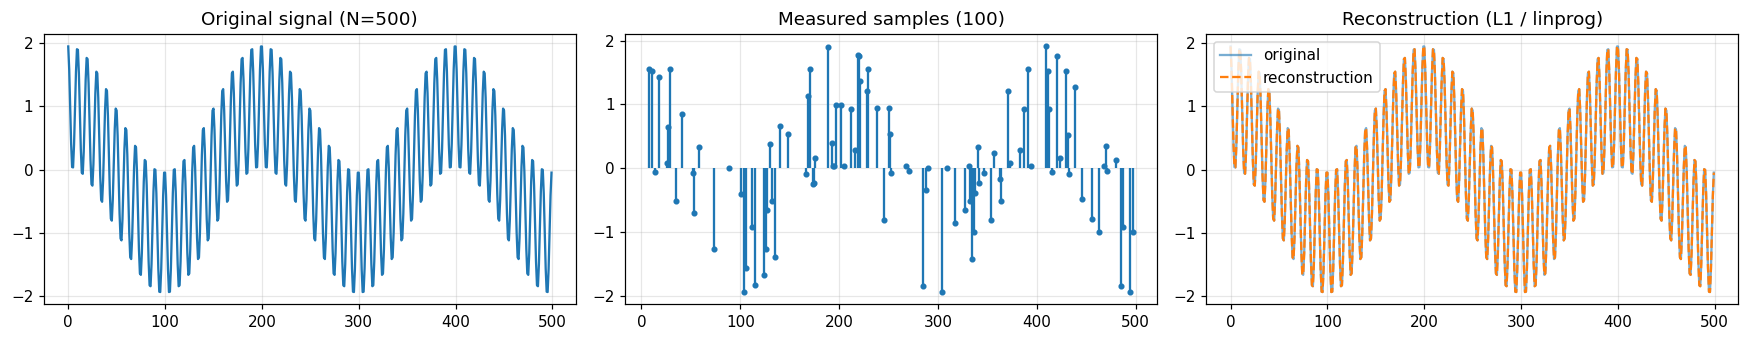

In [25]:
from scipy import fftpack
from scipy.optimize import linprog

N, n_samples = 500, 100                    # only 100 out of 500 samples (20%)
k = np.arange(N) + 0.5                                    # sample grid consistent with the DCT-II basis
x = np.cos(2*np.pi*k/10) + np.cos(2*np.pi*k/200)         # exactly 2 non-zero DCT coefficients

rng = np.random.default_rng(1)
idx = np.sort(rng.choice(N, n_samples, replace=False))   # random sample positions
y = x[idx]

# Note: the original notebook uses sines, which are not exactly sparse in DCT-II, so the reconstruction
# there is noisy. Cosines on the (k+0.5) grid give an almost perfect reconstruction.
# IDCT matrix (columns = basis vectors); rows = measured samples only
Psi = fftpack.idct(np.eye(N), norm="ortho", axis=0)
A = Psi[idx, :]

# min ||X||_1  s.t.  A X = y   ->   X = u - v, u,v >= 0
c = np.ones(2 * N)
res = linprog(c, A_eq=np.hstack([A, -A]), b_eq=y, bounds=(0, None), method="highs")
X = res.x[:N] - res.x[N:]
x_rec = fftpack.idct(X, norm="ortho")

print("status:", res.message)
print(f"relative reconstruction error: {np.linalg.norm(x - x_rec) / np.linalg.norm(x):.2e}")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.2))
ax[0].plot(x); ax[0].set_title("Original signal (N=500)")
ax[1].stem(idx, y, markerfmt=".", basefmt=" "); ax[1].set_title(f"Measured samples ({n_samples})")
ax[2].plot(x, label="original", alpha=.6); ax[2].plot(x_rec, "--", label="reconstruction"); ax[2].legend()
ax[2].set_title("Reconstruction (L1 / linprog)")
plt.tight_layout(); plt.show()

### Results of the compressive sensing experiment

The test signal has N = 500 samples and consists of two cosines. In the DCT domain it has only **2 non-zero coefficients** (indices 5 and 100), i.e. it is exactly sparse. Only **100 randomly chosen samples (20%)** were "measured". The reconstruction was found by basis pursuit: minimise ‖X‖₁ subject to the condition that the IDCT of X matches the measured samples, solved as a linear program (HiGHS). The solver reports *Optimal*, and the **relative reconstruction error is 1.59·10⁻¹²**, i.e. the signal is recovered perfectly, up to numerical precision. In the last plot the reconstruction lies exactly on top of the original, including the fast oscillations that are not visible in the 100 measured points at all.

Compared with the original notebook (`Basic_opt`) this works much better, for two reasons: (1) the L1 problem is formulated as a linear program with a proper equality constraint, so the solver converges, and (2) the signal is exactly sparse in the chosen basis (cosines on the same grid as DCT-II), while sines in the original notebook leak over many DCT coefficients and give a noisy reconstruction. The result shows the main idea of compressive sensing: if the signal is sparse in some basis, a small number of random measurements is enough to recover it, and minimising the L1 norm finds the sparse solution among all signals that agree with the measurements. Note that 100 samples is the number the Nyquist criterion would require for the fastest component (period of 10 samples), but the information in the signal is only 2 numbers (plus 2 positions). The theory says that roughly K·log(N/K) random measurements are enough for K non-zero coefficients, so far fewer samples should also work.

### Where compressive sensing may be useful in EO

- **On-board compression and downlink.** Satellites collect much more data than the downlink can carry. If images are sparse in a wavelet or DCT basis (as natural images are), a small set of random linear measurements can be stored or transmitted instead of all pixels, and the image is reconstructed on the ground, where computing power is not limited. The encoder is simple, which is important for low-power on-board hardware.
- **Cheaper and lighter sensors.** Hyperspectral and multispectral instruments measure hundreds of bands per pixel, which gives a huge data volume. Compressive designs, such as coded-aperture spectrometers or single-pixel cameras, measure fewer combinations of pixels or bands and reconstruct the full data cube afterwards. This allows lighter and cheaper instruments, which is attractive for small satellites and CubeSats.
- **SAR.** Radar images of many scenes are sparse (a few strong scatterers over a dark background, such as ships on the sea or buildings in a city). Compressive sensing can be used to reconstruct images from sub-sampled or incomplete raw data, which reduces the data volume and the acquisition time, can improve resolution and can suppress sidelobes or ambiguities. A related application is SAR tomography and the separation of scatterers in layover areas.
- **Gap filling.** Clouds, sensor failures or missing scan lines remove pixels in a way that is similar to random sampling. If the image is sparse in some basis, the missing part can be estimated by the same L1 optimisation (inpainting). It is also used to fill missing data in time series and in satellite products such as sea surface temperature.
- **Other uses.** Super-resolution and image fusion (e.g. pan-sharpening), denoising (also of SAR speckle) and anomaly or change detection by exploiting sparsity of the changes.

**Limitations.** (1) The signal must be sparse (or compressible) in a known basis such as DCT or wavelets. Natural images are only approximately sparse, so the reconstruction is not exact. (2) The measurements must be random or incoherent with that basis, so regular sampling patterns (e.g. cloud gaps, missing lines) are less favourable than random ones. (3) Noise and approximate sparsity require a robust formulation (basis pursuit denoising or LASSO), and the error then depends on the noise level. (4) Reconstruction is computationally expensive, and it is done on the ground. (5) In operational EO many of these ideas are still at the research or experimental stage, and classic compression (JPEG 2000, CCSDS standards) is still the main approach on most missions.